# Squares in Squares: the whole project, step by step

This notebook walks through everything done in this repository for the Kaggle
competition [Squares in Squares](https://www.kaggle.com/competitions/squares-in-squares),
from the all-grid baseline (**28.94**) to the current submission (**22.2570**).
Every number is recomputed from `best/` and `submission_final.csv`, and every
picture is drawn from the stored packings. A prose version is in
[`WALKTHROUGH.md`](WALKTHROUGH.md).

Run it from the repository root, with the packages in `requirements.txt`.

**Contents**

1. The problem and the metric
2. The baseline
3. The grader, and how a file loses points silently
4. Published records for `n ≤ 324`
5. Göbel's centred diagonal block
6. The L-lift
7. Friedman's off-centre family and Göbel's diagonal strip
8. Public packings
9. The final file, puzzle by puzzle
10. What did not work
11. Where the gap is, and what comes next

In [1]:
import csv
import json
import math
import tempfile
from collections import Counter
from pathlib import Path

import numpy as np

import squares_core as sc
import viz
import gobel_packings as gp
import lift_packings as lp
import grader_check as gc
from merge_best import separate

FIG = Path(tempfile.mkdtemp())

try:
    from IPython.display import Image, display

    def show(path):
        display(Image(filename=str(path)))
except ImportError:
    def show(path):
        print("figure:", path)


def load(n):
    # Best packing on disk for n: (xy, th, L)
    d = np.load(f"best/n{n:03d}.npz")
    return d["xy"], d["th"], float(d["L"])


def panel(xy, th, label, n=None):
    n = n or len(xy)
    L = sc.container_side(xy, th)
    return {"xy": xy, "th": th, "label": label,
            "note": f"n={n}  L={L:.4f}  score {sc.score(L, n):.4f}"}

## 1. The problem and the metric

For each `n = 1 … 1000`, place `n` unit squares, free to rotate, with disjoint
interiors. The grader wraps the tightest axis-aligned square around them:

$$L = \max(\text{width}, \text{height}), \qquad \text{score}(n) = \frac{L}{\sqrt n} - 1 .$$

The leaderboard is the sum over all 1000 puzzles, lower is better. There are no
walls to respect, only pairwise non-overlap, so a good packing has width ≈ height.

The floor is 0, reached only when the squares tile the container, which happens
exactly when `n` is a perfect square: 31 puzzles are free, 969 are not.

## 2. The baseline

The trivial packing puts `n` squares in a `⌈√n⌉ × ⌈√n⌉` grid.

all-grid score       28.9376699166
perfect squares      31 (score 0 each)
worst grid puzzles    [2, 5, 10, 6, 17, 11]


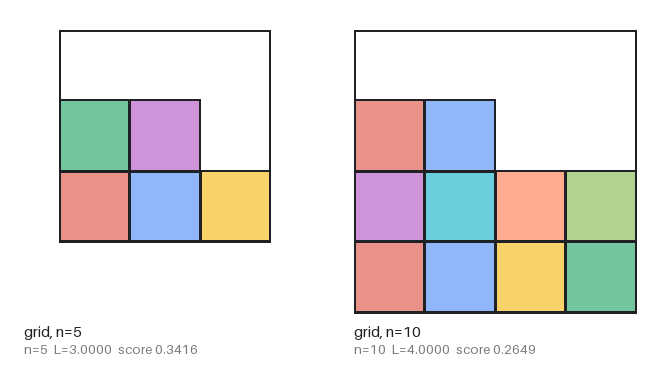

In [2]:
grid_L = {n: sc.grid_side(n) for n in range(1, 1001)}
grid_total = sum(sc.score(grid_L[n], n) for n in grid_L)
perfect = [n for n in grid_L if math.isqrt(n) ** 2 == n]
print(f"all-grid score       {grid_total:.10f}")
print(f"perfect squares      {len(perfect)} (score 0 each)")
print(f"worst grid puzzles   ", sorted(grid_L, key=lambda n: -sc.score(grid_L[n], n))[:6])

xy, th = sc.grid(5)
show(viz.render([panel(xy, th, "grid, n=5"), panel(*sc.grid(10), "grid, n=10")],
                FIG / "grid.png"))

The worst puzzles are `k² + 1`: one extra square forces a whole new row and
column. These are where clever packings pay most.

## 3. The grader, and how a file loses points silently

Kaggle's [metric notebook](https://www.kaggle.com/code/metric/squares-in-squares)
is public. Reading it was the most valuable step of the project, because a
rejected puzzle does not fail the file: it is charged the grid value and the
file still scores. Our early files lost 0.21 this way with no error.

The rules, re-implemented in `grader_check.py`:

- pairs close to contact are certified with `mpmath` interval arithmetic at
  50, 100, 200 and 500 digits;
- a true overlap of **any** size is rejected, even 1e-16;
- exact contact at non-dyadic coordinates can never be certified, so it is
  rejected as undecidable;
- Kaggle reads the CSV as doubles, so the double is what must pass.

Four pairs of unit squares make the point:

In [3]:
def two(x1, x2):
    # Two axis-aligned unit squares side by side, centres at x1 and x2
    return [(repr(x1), "0.0", "0.0"), (repr(x2), "0.0", "0.0")]

cases = {
    "touching at 0.5 | 1.5 (dyadic)":          two(0.5, 1.5),
    "touching at 3.35 | 4.35 (non-dyadic)":    two(3.35, 4.35),
    "overlap of 2e-16":                        two(0.5, 1.4999999999999998),
    "gap of 1e-12":                            two(0.5, 1.5 + 1e-12),
}
for name, rows in cases.items():
    ok, why = gc.verify(rows)
    print(f"{name:40s} {'PASS' if ok else 'REJECT':6s}  {why}")

touching at 0.5 | 1.5 (dyadic)           PASS    feasible
touching at 3.35 | 4.35 (non-dyadic)     REJECT  1 contacts undecidable at 500 digits
overlap of 2e-16                         REJECT  squares 0,1 overlap (certified)
gap of 1e-12                             PASS    feasible


A double-precision separating-axis test calls all four of these fine. The
grader rejects two of them.

Published packings touch exactly, at irrational coordinates such as
`2 + √2/2`, so after rounding to doubles they either overlap by ~1e-16 or touch
undecidably. The fix in `merge_best.py` is to expand each packing about its
centroid by a factor of `1 + 1e-12`. Distances between centres only grow, so
every contact opens, at a cost of about 1e-9 over the whole file.

In [4]:
xy, th, L = load(5)
before = gc.verify(gc.as_literals(*sc.centered(xy, th)))
xy2, th2 = separate(xy, th)
after = gc.verify(gc.as_literals(*sc.centered(xy2, th2)))
print("n=5 as stored      ", before)
print("n=5 after 1e-12    ", after)
print(f"cost in L          {sc.container_side(xy2, th2) - L:.2e}")

n=5 as stored       (False, 'squares 2,4 overlap (certified)')
n=5 after 1e-12     (True, 'feasible')
cost in L          1.71e-12


`grader_check.py` run over a whole file predicted Kaggle's score to 1e-10, and it
is the gate for every submission. Here it is on a sample of the current file
(the full run uses every core and takes a few minutes):

In [5]:
literals = gc.load("submission_final.csv")
sample = [2, 5, 10, 11, 17, 37, 101, 326, 500, 842, 901, 962, 1000]
bad = {n: why for n in sample for ok, why in [gc.verify(literals[n])] if not ok}
print(f"checked {len(sample)} puzzles, rejected: {bad or 'none'}")

checked 13 puzzles, rejected: none


## 4. Published records for `n ≤ 324`

[The Squares Project](https://github.com/jlevy/squares) (CC BY 4.0) publishes the
best-known packing for every `n ≤ 324` as a "witness" file, in three formats:
`corners` (175), `center-basis` (75) and `center-angle` (74), some written in
algebraic number fields. `fetch_witnesses.py` downloads them and
`witness_to_packing.py` turns each into `(x, y, θ)`, normalised to unit squares.

This one step was worth **3.03**. A few of them:

n=  5  L=2.70710678  grid 3  gain 0.1310
n= 10  L=3.70710678  grid 4  gain 0.0926
n= 11  L=3.87708359  grid 4  gain 0.0371
n= 17  L=4.67553009  grid 5  gain 0.0787
n= 18  L=4.82287566  grid 5  gain 0.0417
n= 19  L=4.88561808  grid 5  gain 0.0262
n= 26  L=5.62132034  grid 6  gain 0.0743
n= 37  L=6.59861961  grid 7  gain 0.0660


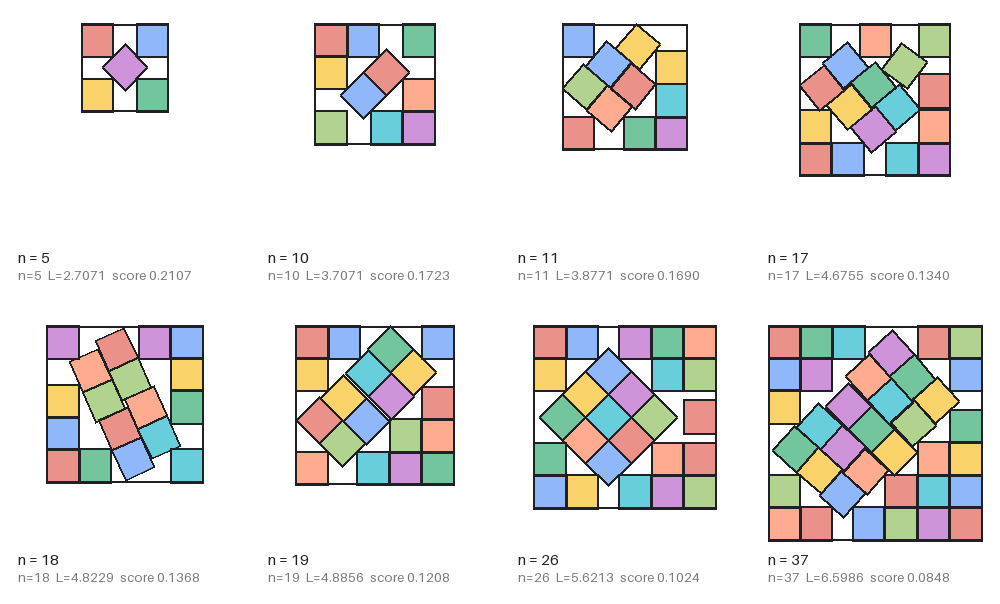

In [6]:
show_n = [5, 10, 11, 17, 18, 19, 26, 37]
show(viz.figure_gallery([panel(*load(n)[:2], f"n = {n}") for n in show_n],
                        FIG / "witnesses.png"))
for n in show_n:
    L = load(n)[2]
    print(f"n={n:3d}  L={L:.8f}  grid {grid_L[n]}  gain {sc.score(grid_L[n], n) - sc.score(L, n):.4f}")

## 5. Göbel's centred diagonal block (`n > 324`)

Nothing was imported above 324, so we built Göbel's family directly
(`gobel_packings.py`). An `a`-deep frame of axis-aligned squares surrounds a
`b × b` block tilted 45°:

$$n = 2a^2 + 2a + b^2 \quad\text{in side}\quad a + 1 + \frac{b}{\sqrt2}, \qquad a - 1 < \frac{b}{\sqrt 2} < a + 1 .$$

For an `n` smaller than the family size, `trim` keeps the `n` squares nearest
the centre. 2,704 builds, none invalid: **1.20**, before lifting spreads it further.

a=3, b=4: n=40, side 6.828427 vs grid 7, valid: True
puzzles 325..1000 where a Göbel build alone beats the grid: 107


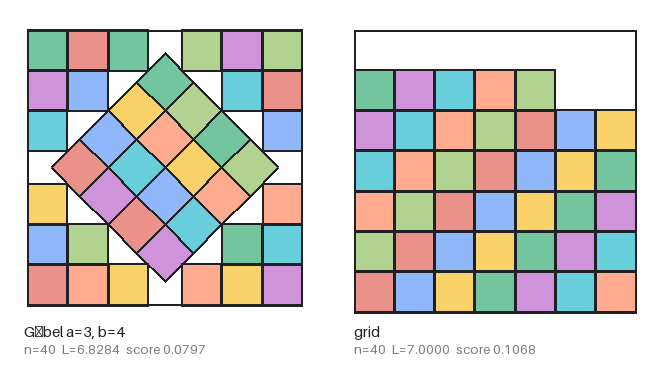

In [7]:
xy, th, side = gp.build(3, 4)
n = len(xy)
print(f"a=3, b=4: n={n}, side {side:.6f} vs grid {sc.grid_side(n)}, valid: {sc.is_valid(xy, th)[0]}")
show(viz.render([panel(xy, th, "Göbel a=3, b=4"), panel(*sc.grid(n), "grid")],
                FIG / "gobel.png"))

beats = [n for n in range(325, 1001)
         if (c := gp.candidates(n)) and c[0][0] < sc.grid_side(n) - 1e-9]
print(f"puzzles 325..1000 where a Göbel build alone beats the grid: {len(beats)}")

## 6. The L-lift

Take a packing of side `L` and add an L-shaped strip of `2⌊L⌋ + 1` axis-aligned
squares along the top and right. The side grows by exactly 1:

$$s\bigl(n + 2\lfloor s(n)\rfloor + 1\bigr) \le s(n) + 1 .$$

Together with "delete one square from `n + 1`", `lift_packings.py` closes
`best/` under both rules until nothing changes. One good seed then improves a
whole chain. 230 puzzles improved: **1.41**.

lift n=5 (L=2.707107) -> n=10, L=3.707107; stored record for n=10: 3.707107

a chain of lifts in best/:
  n=842  L=29.5208152802
  n=901  L=30.5208152802
  n=962  L=31.5208152802


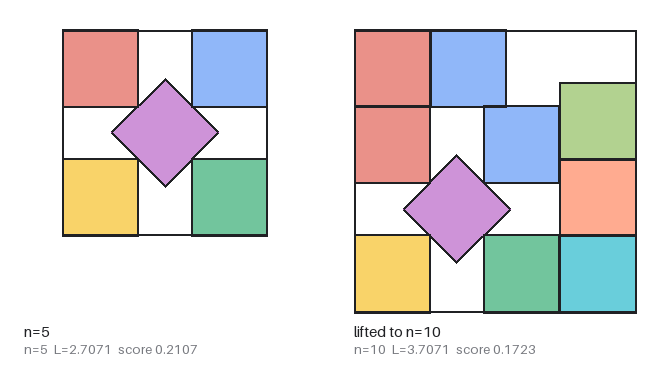

In [8]:
xy, th, L = load(5)
xy, th = sc.centered(xy, th)
big_xy, big_th = lp.lift(xy, th, L)
m = len(big_xy)
print(f"lift n=5 (L={L:.6f}) -> n={m}, L={sc.container_side(big_xy, big_th):.6f}; "
      f"stored record for n={m}: {load(m)[2]:.6f}")
show(viz.render([panel(xy, th, "n=5"), panel(big_xy, big_th, "lifted to n=10")],
                FIG / "lift.png"))

print("\na chain of lifts in best/:")
n = 842
while n <= 1000:
    L = load(n)[2]
    print(f"  n={n}  L={L:.10f}")
    n += 2 * math.floor(L) + 1

The chain `842 → 901 → 962` steps up by exactly 1 each time, which is why the
`k² + 1` records share their decimals across `k = 29, 30, 31`.

## 7. Friedman's off-centre family and Göbel's diagonal strip

Two more constructions from Friedman's survey *Packing Unit Squares in Squares*:

- **Off-centre:** `2a² + 4a + b² + 1` squares in side `a + 3/2 + b/√2`, valid for
  `a − 1/2 < b/√2 < a + 1/2`: the block squeezed into a rectangle, with a column
  of `2a + 1` squares beside it.
- **Diagonal strip:** a 45° strip corner to corner with staircases either side,
  in side `a + 1 + √2/2`.

Only 18 builds above 324 beat what we had, but lifting carried them to 97
puzzles: **0.16**. That brought our own-work score to **22.9888**, confirmed on
Kaggle.

An early estimate of 0.76 here was wrong: it used the parent family's wider
condition `a − 1 < b/√2 < a + 1`, which admits impossible packings such as
`n = 21` at side 4.914.

off-centre a=4,b=6   n=85  side 9.742641  grid 10  valid: True
strip a=4            n=27  side 5.707107  grid 6  valid: True


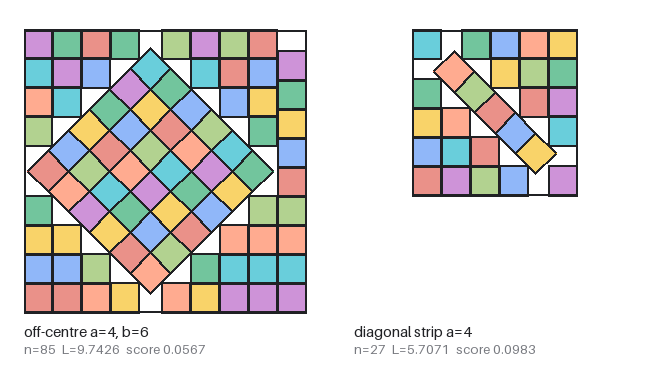

In [9]:
oxy, oth, oside = gp.build_offcentre(4, 6)
sxy, sth, sside = gp.build_strip(4)
for name, (x, t, s) in {"off-centre a=4,b=6": (oxy, oth, oside),
                        "strip a=4": (sxy, sth, sside)}.items():
    print(f"{name:20s} n={len(x)}  side {s:.6f}  grid {sc.grid_side(len(x))}  "
          f"valid: {sc.is_valid(x, t)[0]}")
show(viz.render([panel(oxy, oth, "off-centre a=4, b=6"), panel(sxy, sth, "diagonal strip a=4")],
                FIG / "friedman.png"))

## 8. Public packings

Most of the leaderboard sat between 22.18 and 22.72 because public notebooks
merge everyone's published packings. `merge_public.py` imports a public
`submission.csv`, re-certifies every puzzle with the grader rules, keeps only
improvements, and records each source in `best/provenance.json`. From
malyshevdanil's *Living Atlas of Tight Packings* output this took 578 puzzles,
and a later `make_submission.py --refresh` took 36 more: **0.73**.

Whether rule C.14(a), "your own original work", allows this has no official
answer yet. Deleting the files listed in `best/provenance.json` reverts to the
own-work set.

In [10]:
prov = {int(k): v for k, v in json.loads(Path("best/provenance.json").read_text()).items()}
print("public puzzles by source:", dict(Counter(prov.values())))
print(f"range of n: {min(prov)} .. {max(prov)}; below 325: {sum(n < 325 for n in prov)}")

public puzzles by source: {'submission.csv': 36, 'living_atlas.csv': 578}
range of n: 232 .. 1000; below 325: 2


Note that a refresh pulled only 36 newer packings, and a contact-LP polish of
all 547 public packings above the witness range (`polish_best.py`) gained just
1.8e-8 in total: the public set is already tight.

## 9. The final file, puzzle by puzzle

In [11]:
rows = {}
with open("submission_final.csv", newline="") as f:
    for r in csv.DictReader(f):
        rows.setdefault(int(r["n"]), []).append((float(r["x"]), float(r["y"]), float(r["angle"])))

final_L = {}
for n, rs in rows.items():
    a = np.array(rs)
    final_L[n] = sc.container_side(a[:, :2], a[:, 2])

total = sum(sc.score(final_L[n], n) for n in final_L)
kind = {n: "grid" if final_L[n] > grid_L[n] - 1e-9 else
           "public" if n in prov else "own" for n in final_L}
print(f"puzzles in file      {len(final_L)}")
print(f"score (double test)  {total:.10f}")
print(f"gain over grid       {grid_total - total:.4f}")
for k in ("own", "public", "grid"):
    ns = [n for n in kind if kind[n] == k]
    print(f"  {k:7s} {len(ns):4d} puzzles, score {sum(sc.score(final_L[n], n) for n in ns):8.4f}")

puzzles in file      1000
score (double test)  22.2569857322
gain over grid       6.6807
  own      212 puzzles, score   8.5573
  public   335 puzzles, score   6.4143
  grid     453 puzzles, score   7.2854


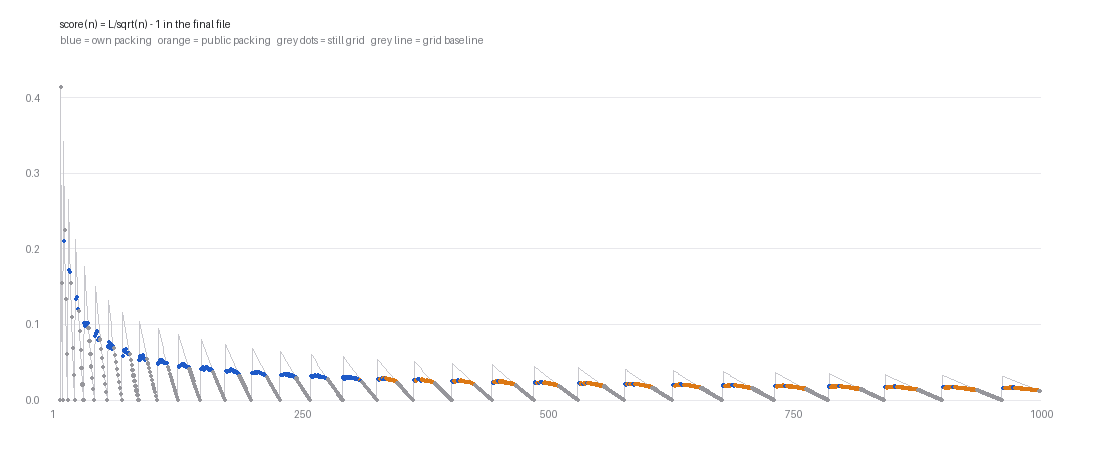

In [12]:
from PIL import Image as PImage, ImageDraw

W, H, P = 1100, 460, 60
img = PImage.new("RGB", (W, H), "white")
d = ImageDraw.Draw(img)
ymax = 0.45
X = lambda n: P + (n - 1) / 999 * (W - 2 * P)
Y = lambda v: H - P - v / ymax * (H - 2 * P)
for v in (0.0, 0.1, 0.2, 0.3, 0.4):
    d.line([(P, Y(v)), (W - P, Y(v))], fill=(232, 232, 236))
    d.text((P - 34, Y(v) - 6), f"{v:.1f}", fill=(120, 122, 128))
for n in (1, 250, 500, 750, 1000):
    d.text((X(n) - 10, H - P + 8), str(n), fill=(120, 122, 128))
d.line([(X(n), Y(sc.score(grid_L[n], n))) for n in range(1, 1001)], fill=(200, 200, 205))
colour = {"own": (30, 90, 200), "public": (220, 120, 20), "grid": (150, 150, 155)}
for n, L in final_L.items():
    x, y = X(n), Y(sc.score(L, n))
    d.ellipse([x - 1.6, y - 1.6, x + 1.6, y + 1.6], fill=colour[kind[n]])
d.text((P, 18), "score(n) = L/sqrt(n) - 1 in the final file", fill=(32, 33, 36))
d.text((P, 34), "blue = own packing   orange = public packing   grey dots = still grid   "
                "grey line = grid baseline", fill=(120, 122, 128))
img.save(FIG / "per_puzzle.png")
show(FIG / "per_puzzle.png")

## 10. What did not work

| attempt | result | why |
|---|---|---|
| `shrink`, `sa_feasible` (`squares_core.py`) | no records | `shrink` never leaves the grid; `sa_feasible` only polishes |
| contact-LP polisher (`contact_polish.py`) on our packings | gain 0 | our packings are jammed: the LP's best step is `dL ≈ +7e-10` |
| the same LP after a random kick | worse | a kick big enough to unjam costs 1–2% of `L`; 300 LP steps win back 15–25% of it |
| the same LP over the public packings (`polish_best.py`) | 1.8e-8 in total | already polished; 95% of it at `n = 916` |
| batched penalty search (`gpu_search.py`) | fails below the record | angle errors add up along rows of 16–20 squares; the penalty settles in tangled minima at `E ≈ 1e-4` |
| a private GPU search kernel on Kaggle | did not run | the account got no GPU or internet; staged for later |

The contact LP itself is sound. It needs unjammed starting packings, which the
public GPU searches produce and our constructions do not.

## 11. Where the gap is, and what comes next

In [13]:
at_grid = [n for n in final_L if kind[n] == "grid"]
locked = [n for n in at_grid if (k := math.isqrt(n - 1) + 1) ** 2 - n in (0, 1, 2)]
open_ = [n for n in at_grid if n not in locked]
print(f"puzzles still at the grid  {len(at_grid):4d}  score {sum(sc.score(grid_L[n], n) for n in at_grid):.4f}")
print(f"  provably locked (k², k²-1, k²-2) {len(locked):4d}  score {sum(sc.score(grid_L[n], n) for n in locked):.4f}")
print(f"  open                             {len(open_):4d}  score {sum(sc.score(grid_L[n], n) for n in open_):.4f}")

puzzles still at the grid   453  score 7.2854
  provably locked (k², k²-1, k²-2)   91  score 1.1567
  open                              362  score 6.1287


- 387 records above `n = 324` cannot be derived from any other record by lifting
  or deleting. They need new packings, and the ~0.2 gap to #1 (22.0544 on
  2026-11-02) lives there.
- The grid tail is a frontier, not a wall: `n = 877` already beats side 30 while
  `878 … 900` are merely unbeaten.

Next:

1. New unjammed starting packings, from a global search with rigid row and block
   moves or from new constructions, finished by the contact LP.
2. Rank seeds by chain value: an improvement at `n` counts once per lift it
   propagates to.
3. Attack the frontier at `k² − (j_min − 1)`.
4. Relaunch the Kaggle GPU kernel once the account has GPU access.

To rebuild everything:

```bash
python src/fetch_witnesses.py
python make_submission.py            # about 15 minutes on 8 cores
python notebooks/build_walkthrough_notebook.py # this notebook
```